In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Veri setini yükle
df = pd.read_csv("diabetes.csv")

# İlk 5 satırı görüntüle
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Veri setinin boyutu
df.shape

(768, 9)

In [4]:
# Veri tipleri ve eksik değerler
print(df.dtypes)
print("\nEksik değerler:")
print(df.isnull().sum())

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Eksik değerler:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [5]:
# Giriş ve çıkış değişkenlerini ayır
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("X:", X.shape)
print("y:", y.shape)

# Sınıf dağılımı
print("\nOutcome dağılımı:")
print(y.value_counts())

X: (768, 8)
y: (768,)

Outcome dağılımı:
Outcome
0    500
1    268
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split

# %80 eğitim, %20 test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Eğitim:", X_train.shape)
print("Test:", X_test.shape)

Eğitim: (614, 8)
Test: (154, 8)


In [7]:
from sklearn.preprocessing import StandardScaler

# Standardizasyon
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
from sklearn.linear_model import LogisticRegression

# Modeli oluştur ve eğit
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# Test verisinde tahmin yap
y_pred = model.predict(X_test_scaled)

y_pred[:10]

array([1, 0, 0, 0, 0, 0, 0, 1, 0, 1])

In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Performans metrikleri
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# ROC-AUC için olasılık tahmini
y_prob = model.predict_proba(X_test_scaled)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

Accuracy: 0.7143
Precision: 0.6087
Recall: 0.5185
F1 Score: 0.56
ROC-AUC: 0.823


In [10]:
from sklearn.metrics import confusion_matrix

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[82 18]
 [26 28]]


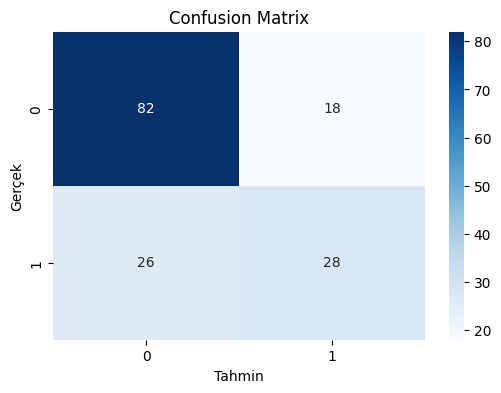

In [11]:
# Confusion matrix görselleştirme
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["0", "1"],
    yticklabels=["0", "1"]
)

plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.title("Confusion Matrix")
plt.show()

In [12]:
from sklearn.metrics import classification_report

# Sınıflandırma raporu
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.76      0.82      0.79       100
           1       0.61      0.52      0.56        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.71      0.71      0.71       154



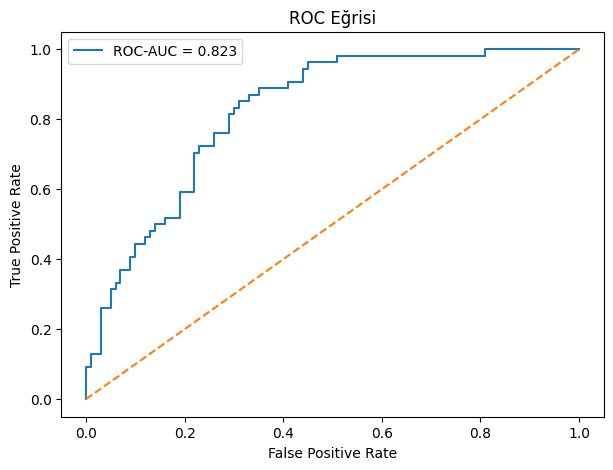

In [13]:
from sklearn.metrics import roc_curve

# ROC eğrisi
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Eğrisi")
plt.legend()
plt.show()

## Sonuç

Logistic Regression modeli test verisinde yaklaşık %71 doğruluk elde etti. ROC-AUC değeri 0.823 olarak bulundu.

Diyabet olmayan sınıfta recall değeri %82 iken, diyabet olan sınıfta %52 olarak elde edildi. Confusion matrix sonucunda 28 diyabetli kişi doğru tahmin edilirken 26 diyabetli kişi negatif olarak sınıflandırıldı.

Bu nedenle model genel olarak iki sınıfı ayırabiliyor olsa da diyabet olan kişileri tespit etme performansı daha düşük kaldı. Test verisindeki sınıf dağılımı da dengeli olmadığı için modeli yalnızca accuracy değeri üzerinden değerlendirmek yeterli değildir.